In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
orders = pd.read_csv("Orders_Cleaned.csv")
customers = pd.read_csv("Customers_Cleaned.csv")
restaurants = pd.read_csv("Restaurants_Cleaned.csv")
delivery = pd.read_csv("Delivery_Cleaned.csv")
ratings = pd.read_csv("Ratings_Cleaned.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [2]:
print(orders.columns.tolist())
orders["Order_Date_Time"] = pd.to_datetime(
    orders["Order_Date_Time"],
    errors="coerce"
)
daily_orders = orders.groupby(
    orders["Order_Date_Time"].dt.date
).size().reset_index(name="Total_Orders")

print(daily_orders)

['Order_Id', 'Customer_Id', 'Restaurant_Id', 'Order_Date_Time', 'Order_Value', 'Payment_Mode', 'Order_Status']
   Order_Date_Time  Total_Orders
0       2026-03-01             6
1       2026-03-02             3
2       2026-03-03             3
3       2026-03-04             2
4       2026-03-05             3
5       2026-03-06             3
6       2026-04-07             3
7       2026-05-08             3
8       2026-06-12             3
9       2026-07-15             2
10      2026-07-16             3
11      2026-09-17             3
12      2026-10-19             3
13      2026-10-20             3
14      2026-10-21             3
15      2026-10-22             3
16      2026-10-23             1


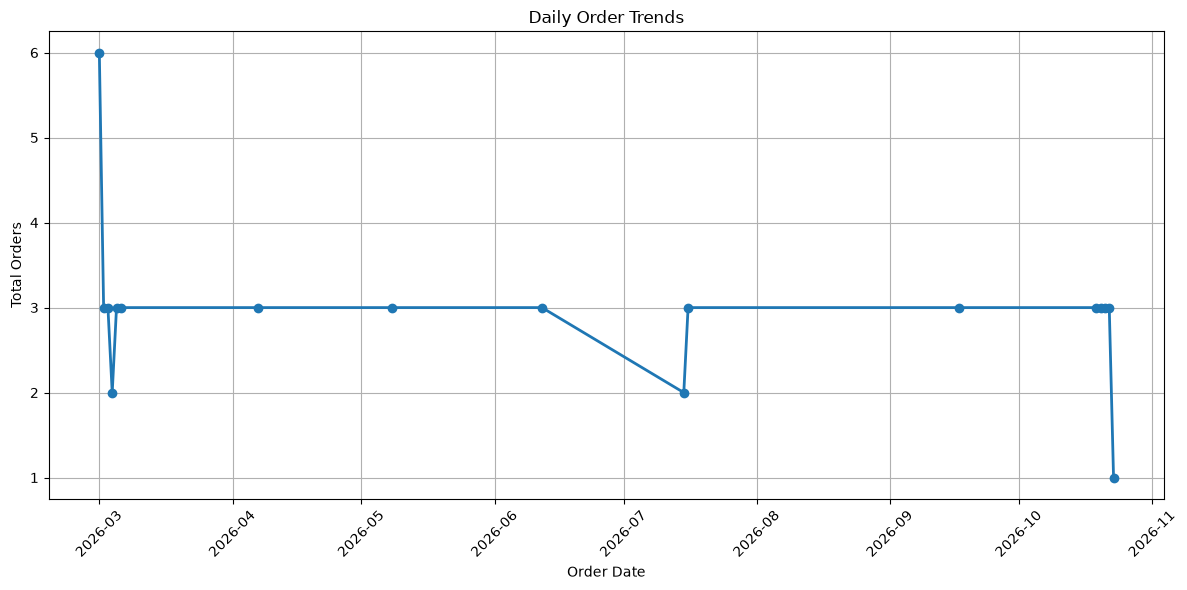

In [4]:
plt.figure(figsize=(12, 6))

plt.plot(
    daily_orders["Order_Date_Time"],
    daily_orders["Total_Orders"],
    marker="o",
    linewidth=2
)

plt.title("Daily Order Trends")
plt.xlabel("Order Date")
plt.ylabel("Total Orders")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [5]:
print(orders.columns.tolist())
orders["Order_Date_Time"] = pd.to_datetime(
    orders["Order_Date_Time"],
    errors="coerce"
)
monthly_revenue = orders[
    orders["Order_Status"].str.strip().str.title() == "Delivered"
].copy()

monthly_revenue["Month"] = (
    monthly_revenue["Order_Date_Time"].dt.to_period("M")
)

monthly_revenue = monthly_revenue.groupby(
    "Month"
)["Order_Value"].sum().reset_index()

monthly_revenue["Month"] = monthly_revenue["Month"].astype(str)

print(monthly_revenue)


['Order_Id', 'Customer_Id', 'Restaurant_Id', 'Order_Date_Time', 'Order_Value', 'Payment_Mode', 'Order_Status']
     Month  Order_Value
0  2026-03         8530
1  2026-04         1620
2  2026-05          589
3  2026-06         1348
4  2026-07         2707
5  2026-09          560
6  2026-10         6290


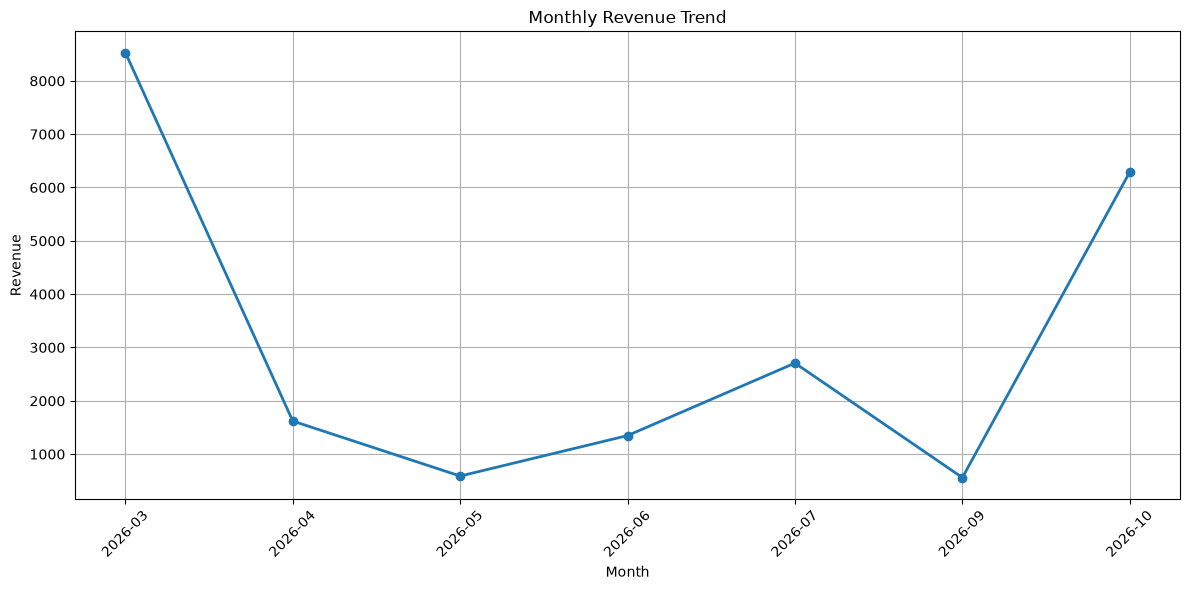

In [6]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue["Month"],
    monthly_revenue["Order_Value"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [7]:
print(orders.columns.tolist())
print(restaurants.columns.tolist())
delivered_orders = orders[
    orders["Order_Status"].str.strip().str.title() == "Delivered"
].copy()
restaurant_revenue = delivered_orders.groupby(
    "Restaurant_Id"
)["Order_Value"].sum().reset_index()
restaurant_revenue = restaurant_revenue.merge(
    restaurants[["Restaurant_Id", "Restaurant_Name"]],
    on="Restaurant_Id",
    how="left"
)
top_10_restaurants = restaurant_revenue.sort_values(
    by="Order_Value",
    ascending=False
).head(10)

display(top_10_restaurants)

['Order_Id', 'Customer_Id', 'Restaurant_Id', 'Order_Date_Time', 'Order_Value', 'Payment_Mode', 'Order_Status']
['Restaurant_Id', 'Restaurant_Name', 'Cuisine', 'City', 'Rating']


,Restaurant_Id,Order_Value,Restaurant_Name
0,REST01,1800,A2B
22,REST39,995,Benjarong
21,REST38,994,Thai Naam
3,REST06,990,Ponnusamy
18,REST32,945,Chili'S
17,REST29,930,Subway
8,REST15,900,Absolute Barbecues
2,REST05,890,Annapoorna
13,REST21,890,Domino'S Pizza
16,REST27,850,Mcdonald'S


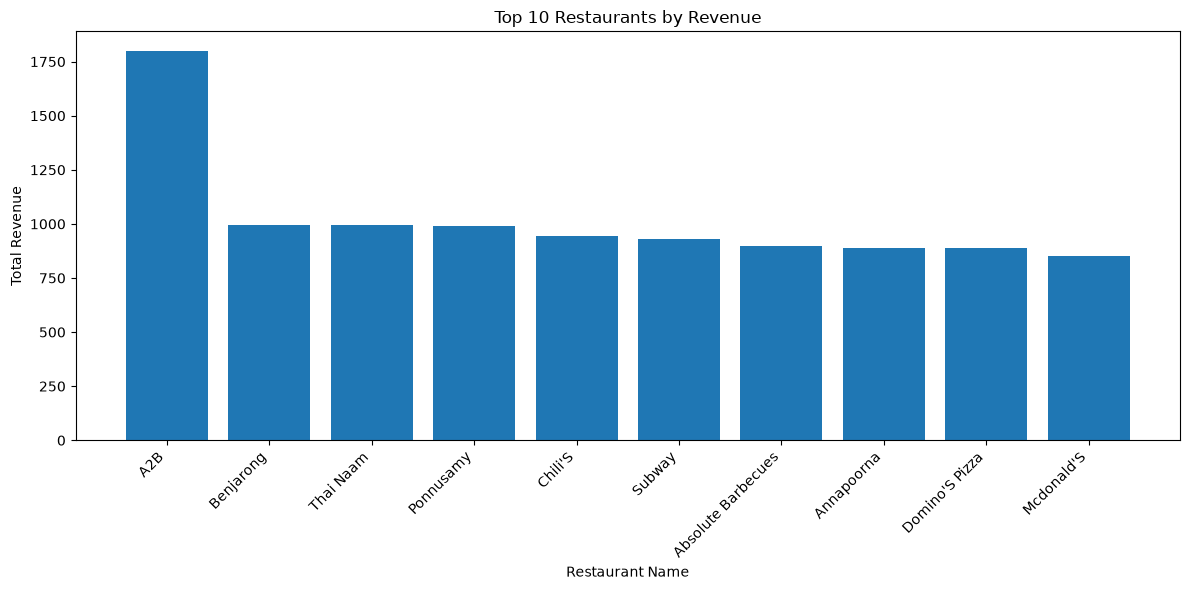

In [8]:
plt.figure(figsize=(12, 6))

plt.bar(
    top_10_restaurants["Restaurant_Name"],
    top_10_restaurants["Order_Value"]
)

plt.title("Top 10 Restaurants by Revenue")
plt.xlabel("Restaurant Name")
plt.ylabel("Total Revenue")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

In [7]:
import os

print("Current Folder:")
print(os.getcwd())

print("\nAvailable Files:")
print(os.listdir())

Current Folder:
c:\Users\New\Desktop\Food delivery project

Available Files:
['DataCleaning.ipynb', 'Dataset', 'EDA.ipynb', 'Python']


In [8]:
import os

print(os.listdir("Dataset"))

['1)Orders.csv', '2) Customers.csv', '3)Restuarant.csv', '4)Delivery.csv', '5)Ratings.csv']


In [3]:
import os

print("Current Working Directory:")
print(os.getcwd())

print("\nFiles in current folder:")
print(os.listdir())

Current Working Directory:
c:\Users\New\Desktop\Food delivery project

Files in current folder:
['Dataset', 'EDA.ipynb', 'Python']


In [4]:
import os

print(os.listdir("Python"))

['1)Data_Cleaning.ipynb', 'Customers_Cleaned.csv', 'Delivery_Cleaned.csv', 'Orders_Cleaned.csv', 'Ratings_Cleaned.csv', 'Restaurants_Cleaned.csv']


In [14]:


orders = pd.read_csv("Python/Orders_Cleaned.csv")
restaurants = pd.read_csv("Python/Restaurants_Cleaned.csv")

print("Datasets loaded successfully!")

Datasets loaded successfully!


In [11]:
cuisine_data = orders.merge(
    restaurants[["Restaurant_Id", "Cuisine"]],
    on="Restaurant_Id",
    how="left"
)

In [12]:
cuisine_data = cuisine_data[
    cuisine_data["Order_Status"].str.strip().str.title() == "Delivered"
]
popular_cuisines = cuisine_data["Cuisine"].value_counts().reset_index()

popular_cuisines.columns = ["Cuisine", "Total_Orders"]

top_10_cuisines = popular_cuisines.head(10)

display(top_10_cuisines)

,Cuisine,Total_Orders
0,South Indian,6
1,North Indian,4
2,Italian,3
3,Hyderabadi,2
4,Fast Food,2
5,Chinese,2
6,Thai,2
7,Chettinad,1
8,Biryani,1
9,Mughlai,1


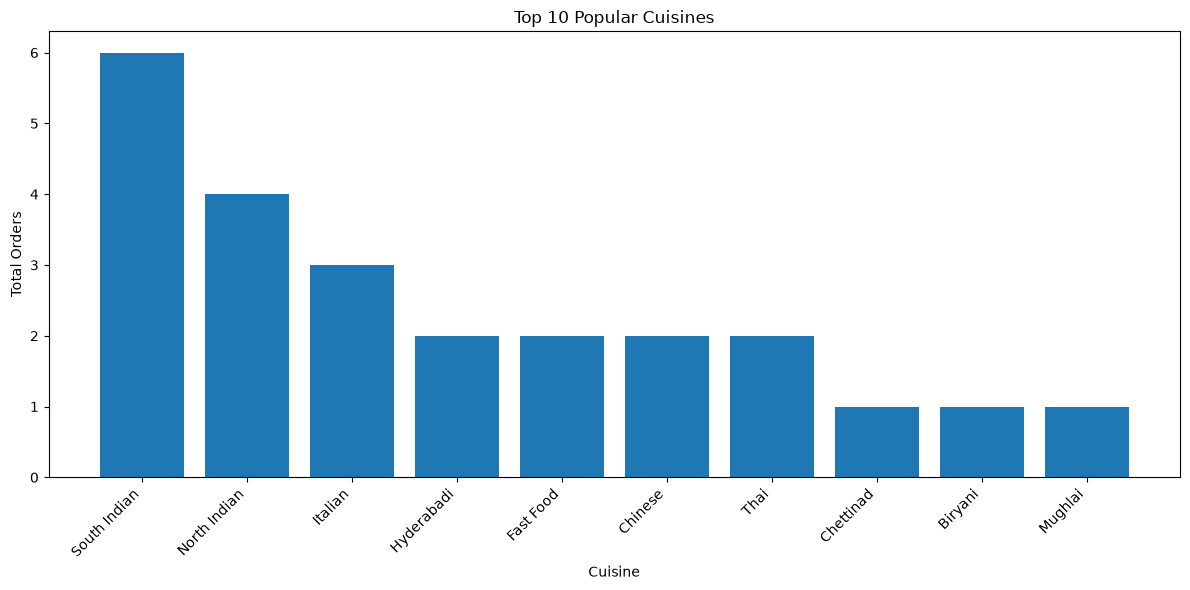

In [15]:
plt.figure(figsize=(12, 6))

plt.bar(
    top_10_cuisines["Cuisine"],
    top_10_cuisines["Total_Orders"]
)

plt.title("Top 10 Popular Cuisines")
plt.xlabel("Cuisine")
plt.ylabel("Total Orders")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

In [20]:
import os

print("Current Working Directory:")
print(os.getcwd())

print("\nFiles Available:")
print(os.listdir())

Current Working Directory:
c:\Users\New\Desktop\Food delivery project\Python

Files Available:
['1)Data_Cleaning.ipynb', 'Customers_Cleaned.csv', 'Delivery_Cleaned.csv', 'Orders_Cleaned.csv', 'Ratings_Cleaned.csv', 'Restaurants_Cleaned.csv', 'Z_EDA.ipynb']


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

orders = pd.read_csv("Orders_Cleaned.csv")
customers = pd.read_csv("Customers_Cleaned.csv")
restaurants = pd.read_csv("Restaurants_Cleaned.csv")
delivery = pd.read_csv("Delivery_Cleaned.csv")
ratings = pd.read_csv("Ratings_Cleaned.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


Payment_Mode
Credit Card    23
Debit Card     16
UPI            10
Cash            1
Name: count, dtype: int64


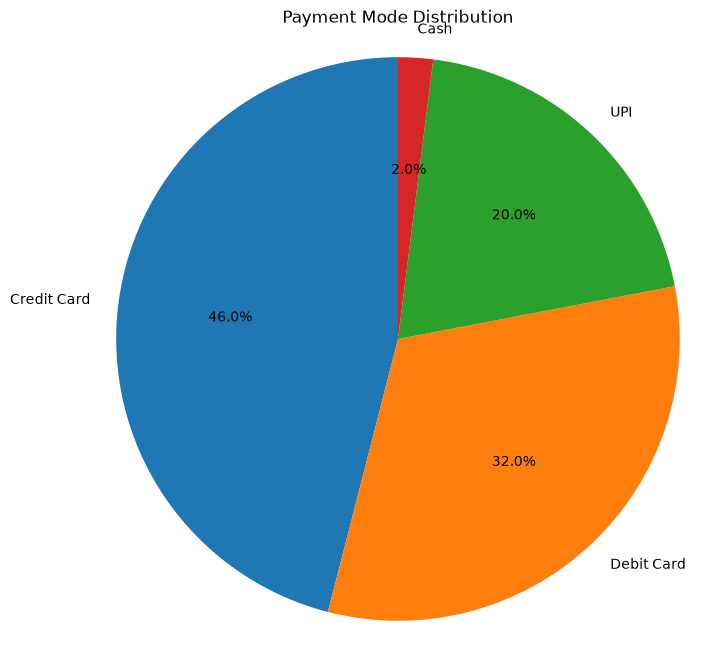

In [23]:
payment_counts = orders["Payment_Mode"].value_counts()

print(payment_counts)
plt.figure(figsize=(8, 8))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Payment Mode Distribution")

plt.axis("equal")

plt.show()

In [25]:
delivery = pd.read_csv("Delivery_Cleaned.csv")

print("Delivery dataset loaded successfully!")
print(delivery.columns.tolist())

Delivery dataset loaded successfully!
['Delivery_ID', 'Order_ID', 'Agent_ID', 'Distance_KM', 'Delivery_Time', 'Delay_Status']


0    20
1    25
2    25
3    25
4    25
5    20
6    20
7    20
8    25
9    25
Name: Delivery_Time, dtype: int64
int64


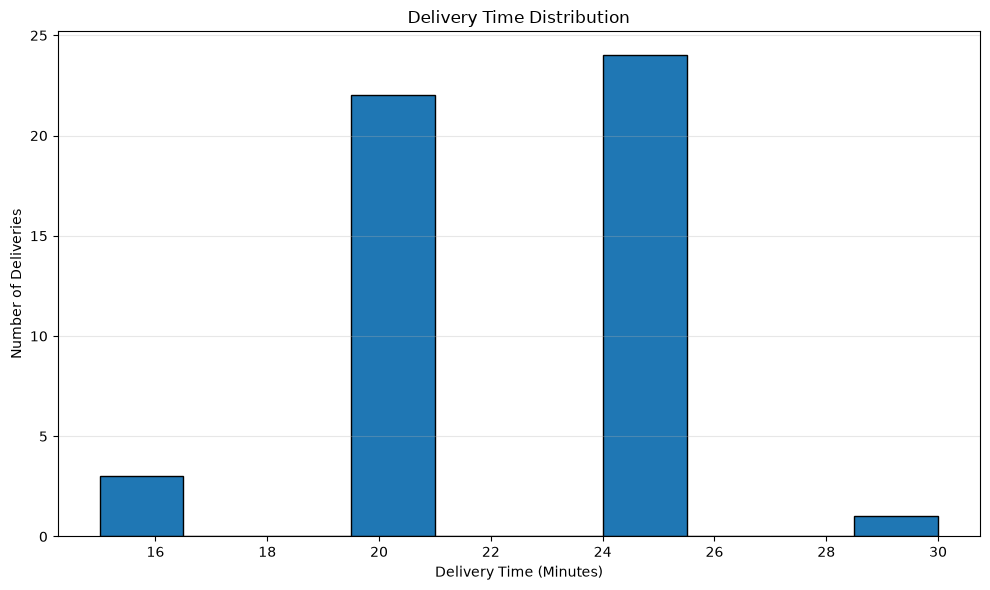

In [26]:
print(delivery["Delivery_Time"].head(10))

print(delivery["Delivery_Time"].dtype)
delivery["Delivery_Time"] = pd.to_numeric(
    delivery["Delivery_Time"],
    errors="coerce"
)
plt.figure(figsize=(10, 6))

plt.hist(
    delivery["Delivery_Time"].dropna(),
    bins=10,
    edgecolor="black"
)

plt.title("Delivery Time Distribution")
plt.xlabel("Delivery Time (Minutes)")
plt.ylabel("Number of Deliveries")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [28]:
ratings = pd.read_csv("Ratings_Cleaned.csv")

print("Ratings dataset loaded successfully!")

print(ratings.columns.tolist())

Ratings dataset loaded successfully!
['Rating_ID', 'Order_ID', 'Customer_Rating', 'Feedback']


In [29]:
delivery_rating = delivery.merge(
    ratings[["Order_ID", "Customer_Rating"]],
    on="Order_ID",
    how="inner"
)

print("Delivery and Ratings datasets merged successfully!")

display(delivery_rating.head())

Delivery and Ratings datasets merged successfully!


,Delivery_ID,Order_ID,Agent_ID,Distance_KM,Delivery_Time,Delay_Status,Customer_Rating
0,D001,O1001,A101,3.5,20,On Time,5
1,D002,O1002,A102,4.0,25,Delay,4
2,D003,O1003,A103,4.5,25,On Time,5
3,D004,O1004,A104,5.0,25,Delay,3
4,D005,O1005,A105,5.0,25,On Time,4


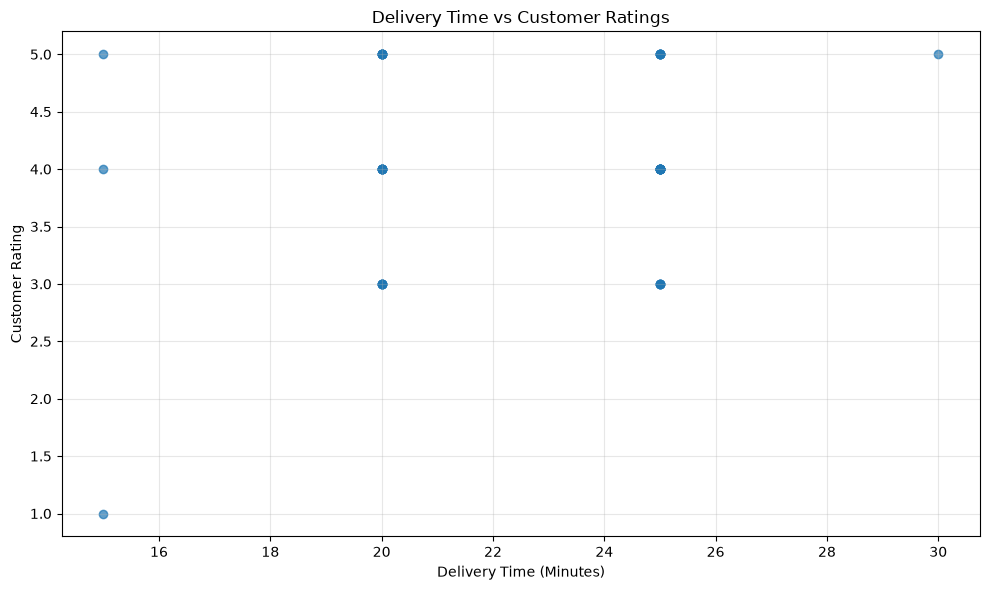

In [30]:
delivery_rating["Delivery_Time"] = pd.to_numeric(
    delivery_rating["Delivery_Time"], errors="coerce"
)

delivery_rating["Customer_Rating"] = pd.to_numeric(
    delivery_rating["Customer_Rating"], errors="coerce"
)

delivery_rating = delivery_rating.dropna(
    subset=["Delivery_Time", "Customer_Rating"]
)

plt.figure(figsize=(10, 6))

plt.scatter(
    delivery_rating["Delivery_Time"],
    delivery_rating["Customer_Rating"],
    alpha=0.7
)

plt.title("Delivery Time vs Customer Ratings")
plt.xlabel("Delivery Time (Minutes)")
plt.ylabel("Customer Rating")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [31]:
# Convert columns to correct data types
orders["Order_Date_Time"] = pd.to_datetime(
    orders["Order_Date_Time"], errors="coerce"
)

orders["Order_Value"] = pd.to_numeric(
    orders["Order_Value"], errors="coerce"
)

# Select delivered orders
rfm_orders = orders[
    orders["Order_Status"].str.strip().str.title() == "Delivered"
].copy()

# Remove rows with missing important values
rfm_orders = rfm_orders.dropna(
    subset=["Customer_Id", "Order_Date_Time", "Order_Value"]
)

print("Delivered orders selected successfully!")
display(rfm_orders.head())

Delivered orders selected successfully!


,Order_Id,Customer_Id,Restaurant_Id,Order_Date_Time,Order_Value,Payment_Mode,Order_Status
0,ORD001,CUST101,REST01,2026-03-01 10:40:00,450,Credit Card,Delivered
3,ORD004,CUST104,REST04,2026-03-02 09:50:00,450,Debit Card,Delivered
4,ORD005,CUST105,REST05,2026-03-02 09:40:00,890,Credit Card,Delivered
5,ORD006,CUST106,REST06,2026-03-02 08:50:00,990,Credit Card,Delivered
8,ORD009,CUST109,REST09,2026-03-03 02:50:00,680,UPI,Delivered


In [32]:
# Reference date
snapshot_date = rfm_orders["Order_Date_Time"].max() + pd.Timedelta(days=1)

# Calculate RFM
rfm = rfm_orders.groupby("Customer_Id").agg(
    Recency=("Order_Date_Time", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Order_Id", "count"),
    Monetary=("Order_Value", "sum")
).reset_index()

display(rfm.head(10))

,Customer_Id,Recency,Frequency,Monetary
0,CUST101,237,4,1800
1,CUST104,236,1,450
2,CUST105,236,1,890
3,CUST106,236,1,990
4,CUST109,235,1,680
5,CUST111,234,1,250
6,CUST112,234,1,550
7,CUST113,233,1,600
8,CUST115,233,1,900
9,CUST116,232,1,400
